<a href="https://colab.research.google.com/github/nattaponm/Teach_Pysteps_KKN_summerStorm/blob/main/notebooks/05_probabilistic_nowcast.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 5: Probabilistic nowcasting — ความน่าจะเป็นของฝนหนัก ณ จุดที่เกิดความเสียหาย
### STEPS ensemble, pixel vs neighbourhood probability, ensemble verification and a cost–loss warning decision

⏱️ เวลาเรียนโดยประมาณ **90 นาที** | ต้องผ่าน: Notebook 1–4

---
## 🎯 วัตถุประสงค์การเรียนรู้
เมื่อจบ notebook นี้ นิสิตจะสามารถ
1. **สร้าง ensemble nowcast ด้วย STEPS** และอธิบายว่าทำไมต้องมีหลาย member
2. **คำนวณแผนที่ความน่าจะเป็น** $P(R > r)$ แบบ pixel และแบบ neighbourhood
3. **สร้างผลิตภัณฑ์เตือนภัย ณ จุด** (นากลาง, สุวรรณคูหา) จาก ensemble
4. **ประเมิน ensemble** ด้วย ROC, reliability diagram และ rank histogram
5. **ตัดสินใจเตือนภัยด้วยแบบจำลอง cost–loss** — เชื่อมวิทยาศาสตร์กับการจัดการภัยพิบัติ

## 📖 1. แนวคิดและสมการ

### 1.1 STEPS (Short-Term Ensemble Prediction System)
S-PROG (NB4) ทำให้ภาพเรียบเพราะสเกลเล็กพยากรณ์ไม่ได้ **STEPS เติม "สัญญาณรบกวนเชิงสุ่ม (stochastic noise)"** ที่มีโครงสร้างเชิงพื้นที่เหมือนฝนจริง แทนส่วนที่พยากรณ์ไม่ได้ และรบกวน motion field ด้วย
→ ได้หลาย **member** ที่ "เป็นไปได้" ทุก member ดูเหมือนฝนจริง ความกระจายระหว่าง member = **ความไม่แน่นอน**

### 1.2 ความน่าจะเป็นแบบ pixel และแบบ neighbourhood
$$ P_{\mathrm{pixel}}(R>r) = \frac{1}{N}\sum_{i=1}^{N}\mathbb{1}\big(R_i(\mathbf{x}) > r\big),\qquad
   P_{\mathrm{nbhd}}(R>r) = \frac{1}{N}\sum_{i=1}^{N}\mathbb{1}\Big(\max_{|\mathbf{y}-\mathbf{x}|\le d} R_i(\mathbf{y}) > r\Big) $$
แบบ neighbourhood ตอบคำถาม **"จะมีฝนหนักภายในรัศมี d km จากหมู่บ้านไหม?"** ซึ่งตรงกับการเตือนภัยจริงมากกว่า

### 1.3 Verification ของความน่าจะเป็น
- **ROC:** เทียบ hit rate กับ false alarm rate เมื่อเปลี่ยนเกณฑ์ความน่าจะเป็น (พื้นที่ใต้กราฟ AUC > 0.5 = มีทักษะ)
- **Reliability diagram:** เมื่อพยากรณ์ว่า "30%" เกิดจริงประมาณ 30% หรือไม่
- **Rank histogram:** ค่าสังเกตตกอยู่ "ตรงกลาง" ของ ensemble หรือหลุดออกด้านใดด้านหนึ่ง (ensemble แคบ/กว้างเกินไป)

### 1.4 แบบจำลอง cost–loss
ถ้าเตือน → เสียค่าป้องกัน $C$ (เช่น อพยพ/ปิดถนน) | ไม่เตือนแต่เกิดเหตุ → เสียหาย $L$
การตัดสินใจที่ดีที่สุด: **เตือนเมื่อ** $P \ge C/L$ — ถ้าความเสียหายสูงกว่าค่าป้องกัน 10 เท่า ควรเตือนตั้งแต่ $P \ge 0.1$

## ⚙️ 2. เตรียมสภาพแวดล้อมและข้อมูล

In [1]:
#@title ⚙️ Setup: ติดตั้งแพ็กเกจและดาวน์โหลดข้อมูล (รันก่อนเสมอ ~2–3 นาทีใน Colab)
import os, sys, warnings
warnings.filterwarnings("ignore")

REPO = "Teach_Pysteps_KKN_summerStorm"
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip install -q pysteps==1.21.5 cartopy netCDF4 geopandas cmweather
    if not os.path.exists(REPO):
        !git clone -q --depth 1 https://github.com/nattaponm/{REPO}.git

for ROOT in [REPO, ".", ".."]:
    if os.path.exists(os.path.join(ROOT, "utils", "kkn_tools.py")):
        break
ROOT = os.path.abspath(ROOT)
sys.path.insert(0, ROOT)
DATA = os.path.join(ROOT, "data")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils.data_io import load_pcappi, time_index
from utils import mapplot as mp
from utils import kkn_tools as kt
mp.set_style()
mp.set_data_dir(DATA)
print("✅ พร้อมใช้งาน | ข้อมูลอยู่ที่:", DATA)

✅ พร้อมใช้งาน | ข้อมูลอยู่ที่: /content/Teach_Pysteps_KKN_summerStorm/data


In [2]:
import contextlib, io
from scipy.ndimage import maximum_filter
from pysteps import motion, nowcasts
from pysteps.utils import transformation
from pysteps.verification import probscores, ensscores

Z, meta = load_pcappi(DATA)
ts = meta["timestamps"]
DT = meta["accutime"]
reports = kt.load_reports(DATA, meta)
date0 = ts[0].replace(hour=0, minute=0)

BOX = kt.box_around(meta, 102.4, 17.45, 100)              # 200 × 200 km: เลย–หนองบัวลำภู–หนองคาย
Zc, mc = kt.crop(Z, meta, BOX)
RAIN = kt.dbz_to_rainrate(Zc, 200, 1.6, hail_cap=55)
COV = mc["coverage"]
meta_r = dict(mc, unit="mm/h", transform=None, threshold=0.1, zerovalue=0.0)
N_LEAD = 8
THR = 10.0                                                # mm/h (≈ 39 dBZ)
print(f"พื้นที่ {RAIN.shape[1]}×{RAIN.shape[2]} km | threshold ฝนหนัก = {THR} mm/h")


def steps_ensemble(i0, n_members=20, n=N_LEAD, seed=24):
    """STEPS ensemble อัตราฝน (member, lead, y, x) จากข้อมูลถึง index i0"""
    R_in = np.nan_to_num(RAIN[i0 - 2:i0 + 1], nan=0.0)
    dbr, md = transformation.dB_transform(R_in, meta_r, threshold=0.1, zerovalue=-15.0)
    V = motion.get_method("LK")(dbr, verbose=False)
    with contextlib.redirect_stdout(io.StringIO()):          # ปิดข้อความของ pysteps
        E = nowcasts.get_method("steps")(dbr, V, n, n_ens_members=n_members, n_cascade_levels=6,
                                         precip_thr=md["threshold"], kmperpixel=1.0, timestep=DT,
                                         noise_method="nonparametric", vel_pert_method="bps",
                                         mask_method="incremental", seed=seed)
    E = transformation.dB_transform(E, md, inverse=True)[0]
    E = np.where(np.isfinite(E) & (E >= 0.1), E, 0.0)
    E[..., ~COV] = np.nan
    return E


def nbhd_prob(E, thr, radius_km):
    """ความน่าจะเป็นแบบ neighbourhood: สัดส่วน member ที่มี R > thr ภายในรัศมี radius_km"""
    r = int(radius_km)
    yy, xx = np.mgrid[-r:r + 1, -r:r + 1]
    fp = np.hypot(yy, xx) <= r
    exc = np.nan_to_num(E) > thr
    mx = np.stack([[maximum_filter(exc[m, l].astype(np.uint8), footprint=fp) for l in range(E.shape[1])]
                   for m in range(E.shape[0])])
    return mx.mean(axis=0)

Pysteps configuration file found at: /usr/local/lib/python3.12/dist-packages/pysteps/pystepsrc



พื้นที่ 200×200 km | threshold ฝนหนัก = 10.0 mm/h


## 🎲 3. Ensemble nowcast ออก 09:00 UTC (16:00 น.) — 30 นาทีก่อนเหตุที่หนองบัวลำภู

ensemble: (20, 8, 200, 200) (member, lead, y, x)


บันทึกรูปแล้ว: figures/nb5_steps_members_and_probability.png, figures/nb5_steps_members_and_probability.pdf


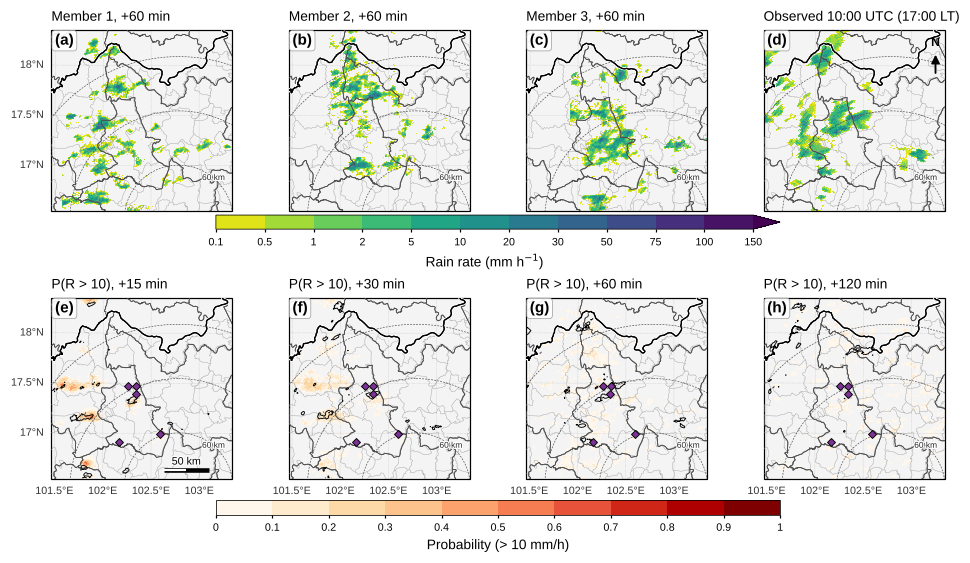

In [3]:
i0 = time_index(meta, "09:00")
ENS = steps_ensemble(i0, n_members=20)
print("ensemble:", ENS.shape, "(member, lead, y, x)")

fig, axs = mp.map_panels(2, 4, mc, panel_width=2.2)
L = 4                                                     # +60 นาที
for k in range(3):
    mp.radar_map(axs[k], ENS[k, L - 1], mc, units="mm/h", title=f"Member {k + 1}, +{L*DT:.0f} min",
                 scalebar=False, north=False, gridline_labels=("left",) if k == 0 else ())
im = mp.radar_map(axs[3], RAIN[i0 + L], mc, units="mm/h", title=f"Observed {mp.tlabel(ts[i0 + L])}",
                  scalebar=False, north=True, gridline_labels=())
for k, LL in enumerate([1, 2, 4, 8]):
    P = np.mean(np.nan_to_num(ENS[:, LL - 1]) > THR, axis=0)
    P[~COV] = np.nan
    imp = mp.radar_map(axs[4 + k], P, mc, ptype="prob", probthr=f"{THR:g} mm/h",
                       title=f"P(R > {THR:g}), +{LL*DT:.0f} min", scalebar=(k == 0), north=False,
                       gridline_labels=(("left",) if k == 0 else ()) + ("bottom",))
    mp.obs_contour(axs[4 + k], RAIN[i0 + LL], mc, level=THR, linewidth=0.6)
    mp.add_reports(axs[4 + k], reports.query("province == 'Nong Bua Lam Phu'"), legend=False, ms=4)
mp.panel_labels(axs)
mp.add_colorbar(fig, im, axs[:4], shrink=0.6)
mp.add_colorbar(fig, imp, axs[4:], shrink=0.6, extend="neither")
mp.save_figure(fig, "nb5_steps_members_and_probability")
plt.show()

แถวบน: **member แต่ละตัวต่างกัน** แต่ "ดูเหมือนฝนจริง" ทุกตัว | แถวล่าง: ความน่าจะเป็นแบบ pixel — เส้นดำ = ฝน ≥ 10 mm/h ที่เกิดจริง
ยิ่ง lead time นาน ความน่าจะเป็นยิ่ง **กระจายและต่ำลง** เพราะความไม่แน่นอนเพิ่มขึ้น

## 📍 4. ผลิตภัณฑ์เตือนภัย: ความน่าจะเป็น ณ นากลางและสุวรรณคูหา

บันทึกรูปแล้ว: figures/nb5_point_probability.png, figures/nb5_point_probability.pdf


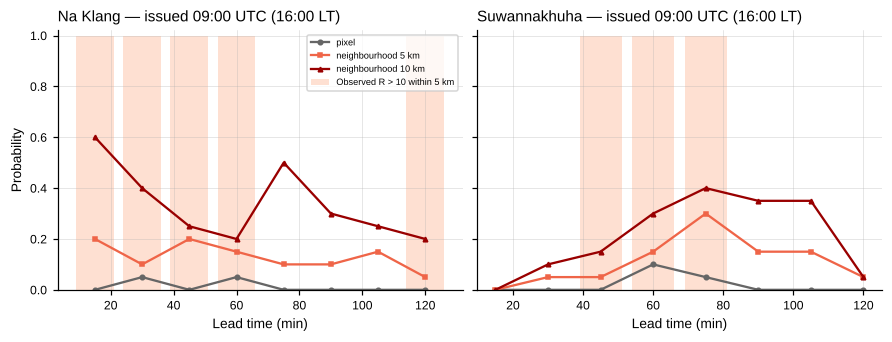

In [4]:
sites = ["Na Klang", "Suwannakhuha"]
lead_min = np.arange(1, N_LEAD + 1) * DT
P_nb5, P_nb10 = nbhd_prob(ENS, THR, 5), nbhd_prob(ENS, THR, 10)
fig, axs = plt.subplots(1, 2, figsize=(8, 3), sharey=True, layout="constrained")
for ax, name in zip(axs, sites):
    r = kt.site(reports, name)
    col, row = [int(round(v)) for v in kt.xy_to_pixel(mc, *kt.lonlat_to_xy(mc, r["lon"], r["lat"]))]
    P_px = np.mean(np.nan_to_num(ENS[:, :, row, col]) > THR, axis=0)
    obs = kt.point_series(RAIN[i0 + 1:i0 + 1 + N_LEAD], mc, r["lon"], r["lat"], 5) > THR
    ax.bar(lead_min[obs], np.ones(obs.sum()), width=12, color="#fee0d2", label="Observed R > 10 within 5 km")
    ax.plot(lead_min, P_px, "o-", color="0.4", ms=3, label="pixel")
    ax.plot(lead_min, P_nb5[:, row, col], "s-", color="#ef6548", ms=3, label="neighbourhood 5 km")
    ax.plot(lead_min, P_nb10[:, row, col], "^-", color="#990000", ms=3, label="neighbourhood 10 km")
    mp.skill_axes(ax, ylabel="Probability" if ax is axs[0] else "", ylim=(0, 1.02),
                  title=f"{name} — issued {mp.tlabel(ts[i0])}")
axs[0].legend(fontsize=6, loc="upper right")
mp.save_figure(fig, "nb5_point_probability")
plt.show()

**pixel** ให้ความน่าจะเป็นต่ำเสมอ (ฝนหนักต้องตกตรง 1 km² พอดี) ส่วน **neighbourhood** ให้ค่าสูงขึ้นและตรงกับคำถามของผู้ใช้มากกว่า
— การเลือกรัศมีคือการแลกเปลี่ยนระหว่าง "ความแม่นยำเชิงตำแหน่ง" กับ "โอกาสจับเหตุการณ์ได้"

## 📏 5. Verification ของ ensemble จาก 5 issue times (08:30–09:30 UTC)

ROC AUC (+30 min, R > 10 mm/h): pixel = 0.52 | neighbourhood 5 km = 0.67
CRPS เฉลี่ย = 0.326 mm/h


บันทึกรูปแล้ว: figures/nb5_ensemble_verification.png, figures/nb5_ensemble_verification.pdf


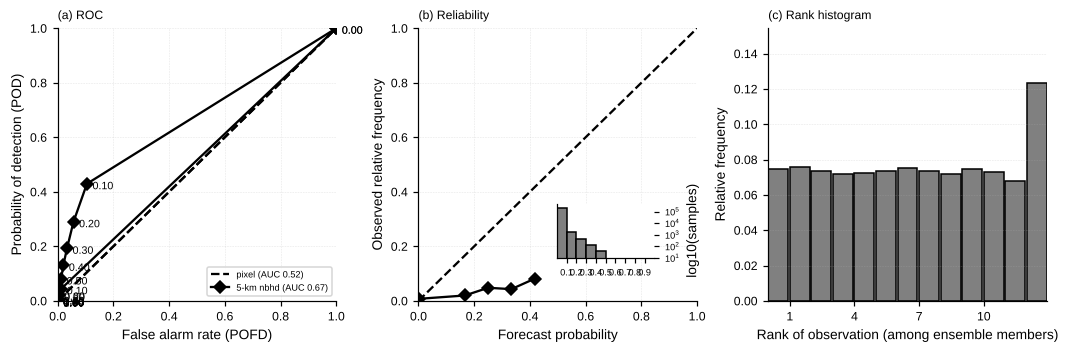

In [5]:
issues = ["08:30", "08:45", "09:00", "09:15", "09:30"]
LV = 2                                                    # verify ที่ lead +30 นาที
roc = probscores.ROC_curve_init(THR, n_prob_thrs=11)
rel = probscores.reldiag_init(THR, n_bins=10)
rh = ensscores.rankhist_init(num_ens_members=12, X_min=0.1)
crps_vals, ENS_V = [], {}
for hh in issues:
    j0 = time_index(meta, hh)
    E = steps_ensemble(j0, n_members=12, seed=7)
    ENS_V[hh] = E
    obs = RAIN[j0 + LV]
    Pm = np.mean(np.nan_to_num(E[:, LV - 1]) > THR, axis=0)
    m = COV & np.isfinite(obs)
    probscores.ROC_curve_accum(roc, np.where(m, Pm, np.nan), np.where(m, obs, np.nan))
    probscores.reldiag_accum(rel, np.where(m, Pm, np.nan), np.where(m, obs, np.nan))
    ensscores.rankhist_accum(rh, np.where(m[None], E[:, LV - 1], np.nan), np.where(m, obs, np.nan))
    crps_vals.append(probscores.CRPS(np.where(m[None], E[:, LV - 1], 0), np.where(m, obs, 0)))
pod, pofd, auc = probscores.ROC_curve_compute(roc, compute_area=True)

# ROC อีกชุด: ถามว่า "มีฝนหนักภายใน 5 km หรือไม่" (neighbourhood) แทน "ตรง pixel นี้หรือไม่"
roc_nb = probscores.ROC_curve_init(0.5, n_prob_thrs=11)
for hh in issues:
    j0 = time_index(meta, hh)
    p_nb = nbhd_prob(ENS_V[hh], THR, 5)[LV - 1]
    ev_nb = maximum_filter((np.nan_to_num(RAIN[j0 + LV]) > THR).astype(np.uint8), size=11).astype(float)
    probscores.ROC_curve_accum(roc_nb, np.where(COV, p_nb, np.nan), np.where(COV, ev_nb, np.nan))
_, _, auc_nb = probscores.ROC_curve_compute(roc_nb, compute_area=True)
print(f"ROC AUC (+{LV*DT:.0f} min, R > {THR:g} mm/h): pixel = {auc:.2f} | neighbourhood 5 km = {auc_nb:.2f}")
print(f"CRPS เฉลี่ย = {np.mean(crps_vals):.3f} mm/h")

from pysteps.verification import plots as vplots
fig, axs = plt.subplots(1, 3, figsize=(9.5, 3.1), layout="constrained")
vplots.plot_ROC(roc, ax=axs[0])
vplots.plot_ROC(roc_nb, ax=axs[0])
lines = axs[0].get_lines()
axs[0].legend([lines[0], lines[-1]], [f"pixel (AUC {auc:.2f})", f"5-km nbhd (AUC {auc_nb:.2f})"], fontsize=6, loc="lower right")
axs[0].set_title("(a) ROC", loc="left", fontsize=8)
vplots.plot_reldiag(rel, ax=axs[1])
axs[1].set_title("(b) Reliability", loc="left", fontsize=8)
vplots.plot_rankhist(rh, ax=axs[2])
axs[2].set_title("(c) Rank histogram", loc="left", fontsize=8)
mp.save_figure(fig, "nb5_ensemble_verification")
plt.show()

- **ROC:** ถ้าเส้นอยู่เหนือเส้นทแยง = ensemble มีทักษะแยกแยะเหตุการณ์ได้ — **ระดับ pixel แทบไม่มีทักษะ (AUC ≈ 0.5)** สำหรับฝนหนักที่ +30 นาที แต่เมื่อถามแบบ **neighbourhood** ทักษะดีขึ้นชัดเจน
  → "คำถาม" ที่ใช้ประเมินสำคัญพอ ๆ กับ "วิธี" nowcast
- **Reliability:** เส้นต่ำกว่าเส้นทแยง = พยากรณ์ความน่าจะเป็นสูงเกินจริง (over-confident)
- **Rank histogram รูปตัว U** = ensemble **แคบเกินไป** (ค่าสังเกตมักหลุดนอกช่วงของ member) — พบบ่อยกับพายุพาความร้อนที่มีเซลล์ใหม่เกิด

---
## 🧪 แบบฝึกหัด

### 🧪 แบบฝึกหัด 5.1: ต้องใช้ member กี่ตัวจึงพอ?
สร้าง ensemble ออก 09:00 UTC ด้วย `n_members` = 5, 10, 20, 40 (แต่ละขนาดใช้ `seed` 3 ค่า เช่น 1, 2, 3) แล้วคำนวณ **ความน่าจะเป็นแบบ neighbourhood 10 km ที่นากลาง lead +15 นาที** พร้อมเวลาที่ใช้คำนวณ

**คำถาม:** ความน่าจะเป็นเปลี่ยนตาม seed มากแค่ไหนเมื่อ member น้อย? ถ้าต้องคำนวณทุก 15 นาทีแบบ real-time ควรเลือกกี่ member?

<details>
<summary><b>💡 คำใบ้ (คลิกเพื่อเปิด)</b></summary>

- `import time` แล้วจับเวลา `t = time.time(); E = steps_ensemble(i0, n_members=n, seed=s, n=1); time.time() - t`
- `P = nbhd_prob(E, THR, 10)` แล้วอ่านค่าที่ `P[0, row, col]` (row, col ของนากลาง ดูโค้ดหัวข้อ 4)

</details>

In [6]:
# ✍️ แบบฝึกหัด 5.1 — เขียนโค้ดของคุณที่นี่ (ลบ # หน้าบรรทัดแล้วเติมส่วนที่เป็น ...)
# import time
# r = kt.site(reports, "Na Klang")
# col, row = ...
# rows = []
# for n in [5, 10, 20, 40]:
#     for s in [1, 2, 3]:
#         ...

In [7]:
#@title ✅ เฉลยแบบฝึกหัด 5.1 (ลองทำเองก่อน! ดับเบิลคลิกเพื่อดูโค้ด แล้วกด ▶ เพื่อรัน)
import time
r = kt.site(reports, "Na Klang")
col, row = [int(round(v)) for v in kt.xy_to_pixel(mc, *kt.lonlat_to_xy(mc, r["lon"], r["lat"]))]
rows = []
for n in [5, 10, 20, 40]:
    for s in [1, 2, 3]:
        t = time.time()
        E = steps_ensemble(i0, n_members=n, seed=s, n=1)
        rows.append({"members": n, "seed": s, "P_nbhd10": nbhd_prob(E, THR, 10)[0, row, col],
                     "seconds": time.time() - t})
mem = pd.DataFrame(rows)
summ = mem.groupby("members").agg(P_mean=("P_nbhd10", "mean"), P_range=("P_nbhd10", lambda v: v.max() - v.min()),
                                  seconds=("seconds", "mean")).round(2)
print(summ)
print("\n→ member น้อย ความน่าจะเป็นกระโดดเป็นขั้นใหญ่ (1/n) และแกว่งตาม seed; 20 member เป็นจุดสมดุลที่ใช้กันทั่วไป")

         P_mean  P_range  seconds
members                          
5          0.47     0.40     0.50
10         0.63     0.30     0.78
20         0.60     0.25     1.43
40         0.63     0.20     2.59

→ member น้อย ความน่าจะเป็นกระโดดเป็นขั้นใหญ่ (1/n) และแกว่งตาม seed; 20 member เป็นจุดสมดุลที่ใช้กันทั่วไป


### 🧪 แบบฝึกหัด 5.2: เมื่อ nowcast พลาด — พายุที่ภูกระดึง
ภูกระดึงเกิดเหตุ **07:00 UTC (14:00 น.)** ออก ensemble 20 member ที่ **06:30 UTC** แล้วหาความน่าจะเป็นแบบ neighbourhood 10 km ที่จุด `Phu Kradueng` ทุก lead time เทียบกับค่าสังเกต
(ต้องสร้างพื้นที่ใหม่ เพราะภูกระดึงอยู่นอกกรอบปัจจุบัน — ใช้ `kt.box_around(meta, 101.9, 16.95, 80)`)

**คำถาม:** ensemble ให้ความน่าจะเป็นสูงหรือไม่? ทำไม nowcast ที่อาศัย "การเลื่อนฝนที่มีอยู่" จึงเตือนพายุที่ **เพิ่งก่อตัว** ไม่ได้?

<details>
<summary><b>💡 คำใบ้</b></summary>

- ฟังก์ชัน `steps_ensemble` ใช้ตัวแปร `RAIN`, `COV`, `meta_r` แบบ global — ให้สร้างชุดใหม่สำหรับพื้นที่ภูกระดึงก่อน แล้วค่อยเรียกฟังก์ชัน
- อย่าลืมคืนค่าตัวแปรเดิมหลังทำเสร็จ (หรือเก็บไว้ในตัวแปรอื่น)

</details>

In [8]:
# ✍️ แบบฝึกหัด 5.2 — เขียนโค้ดของคุณที่นี่

In [9]:
#@title ✅ เฉลยแบบฝึกหัด 5.2
_saved = (RAIN, COV, meta_r, mc)
Zp, mp_meta = kt.crop(Z, meta, kt.box_around(meta, 101.9, 16.95, 80))
RAIN, COV, mc = kt.dbz_to_rainrate(Zp, 200, 1.6, hail_cap=55), mp_meta["coverage"], mp_meta
meta_r = dict(mp_meta, unit="mm/h", transform=None, threshold=0.1, zerovalue=0.0)
j0 = time_index(meta, "06:30")
E = steps_ensemble(j0, n_members=20)
r = kt.site(reports, "Phu Kradueng")
col, row = [int(round(v)) for v in kt.xy_to_pixel(mc, *kt.lonlat_to_xy(mc, r["lon"], r["lat"]))]
Pn = nbhd_prob(E, 5.0, 10)[:, row, col]
obs = kt.point_series(RAIN[j0 + 1:j0 + 1 + N_LEAD], mc, r["lon"], r["lat"], 10)
print(pd.DataFrame({"valid_time": [mp.tlabel(ts[j0 + k]) for k in range(1, N_LEAD + 1)],
                    "P(R>5 within 10 km)": Pn.round(2), "observed max R (mm/h)": obs.round(1)}).to_string(index=False))
RAIN, COV, meta_r, mc = _saved
print("\n→ ฝนที่ภูกระดึงเติบโตจากเซลล์เล็กในเวลาไม่ถึง 30 นาที: ensemble 'เห็น' แค่ฝนที่มีอยู่แล้ว จึงให้ความน่าจะเป็นต่ำหรือเป็นศูนย์"
      "\n  การเตือนพายุที่เพิ่งก่อตัวต้องใช้ข้อมูลสภาพแวดล้อม (CAPE/DCAPE, ดาวเทียม, NWP) ร่วมด้วย")

          valid_time  P(R>5 within 10 km)  observed max R (mm/h)
06:45 UTC (13:45 LT)                 0.00                   23.7
07:00 UTC (14:00 LT)                 0.00                   31.6
07:15 UTC (14:15 LT)                 0.00                   47.9
07:30 UTC (14:30 LT)                 0.00                   25.8
07:45 UTC (14:45 LT)                 0.00                   31.1
08:00 UTC (15:00 LT)                 0.00                    3.2
08:15 UTC (15:15 LT)                 0.05                   19.6
08:30 UTC (15:30 LT)                 0.00                    2.5

→ ฝนที่ภูกระดึงเติบโตจากเซลล์เล็กในเวลาไม่ถึง 30 นาที: ensemble 'เห็น' แค่ฝนที่มีอยู่แล้ว จึงให้ความน่าจะเป็นต่ำหรือเป็นศูนย์
  การเตือนพายุที่เพิ่งก่อตัวต้องใช้ข้อมูลสภาพแวดล้อม (CAPE/DCAPE, ดาวเทียม, NWP) ร่วมด้วย


### 🧪 แบบฝึกหัด 5.3: ปภ. ควรเตือนเมื่อความน่าจะเป็นเท่าไร? (cost–loss)
ใช้ ensemble ทั้ง 5 รอบใน `ENS_V` (lead +30 นาที) และความน่าจะเป็นแบบ neighbourhood 5 km ทุก pixel ในพื้นที่ คำนวณ **ค่าใช้จ่ายเฉลี่ยต่อ pixel** ด้วย `kt.cost_loss_expense(p, event, threshold, C=1, L=L)` สำหรับเกณฑ์ความน่าจะเป็น 0.05–0.9 และอัตราส่วน **C/L = 0.1 (L = 10)** กับ **C/L = 0.3 (L = 3.3)**
เปรียบเทียบกับ "เตือนทุกครั้ง" และ "ไม่เตือนเลย"

**คำถาม:** เกณฑ์ที่ค่าใช้จ่ายต่ำสุดใกล้กับ $C/L$ ตามทฤษฎีหรือไม่? ถ้าเหตุการณ์ทำให้บ้านพัง (L สูงมาก) เกณฑ์ควรสูงหรือต่ำ?

<details>
<summary><b>💡 คำใบ้</b></summary>

- `p = nbhd_prob(ENS_V[hh], THR, 5)[LV - 1]` และ `event = maximum_filter((np.nan_to_num(RAIN[j0 + LV]) > THR).astype(np.uint8), size=11) > 0`
- รวมทุก issue time ด้วย `np.concatenate` เฉพาะ pixel ใน `COV`

</details>

In [10]:
# ✍️ แบบฝึกหัด 5.3 — เขียนโค้ดของคุณที่นี่

C/L = 0.1: เกณฑ์ที่ค่าใช้จ่ายต่ำสุด = 0.05 | เตือนตลอด = 1.00 | ไม่เตือนเลย = 0.93
C/L = 0.3: เกณฑ์ที่ค่าใช้จ่ายต่ำสุด = 0.30 | เตือนตลอด = 1.00 | ไม่เตือนเลย = 0.31


บันทึกรูปแล้ว: figures/nb5_ex53_cost_loss.png, figures/nb5_ex53_cost_loss.pdf


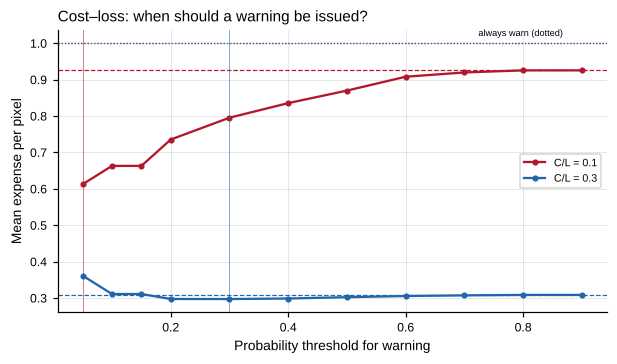

สัดส่วน pixel ที่เกิดเหตุจริง (climatology ของช่วงนี้) = 0.093


In [11]:
#@title ✅ เฉลยแบบฝึกหัด 5.3
ps, evs = [], []
for hh in issues:
    j0 = time_index(meta, hh)
    p = nbhd_prob(ENS_V[hh], THR, 5)[LV - 1]
    ev = maximum_filter((np.nan_to_num(RAIN[j0 + LV]) > THR).astype(np.uint8), size=11) > 0
    ps.append(p[COV])
    evs.append(ev[COV])
p_all, ev_all = np.concatenate(ps), np.concatenate(evs)
thrs = np.array([0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9])
fig, ax = plt.subplots(figsize=(5.5, 3.2), layout="constrained")
for Lc, c in [(10.0, "#b2182b"), (1 / 0.3, "#2166ac")]:
    cost = [kt.cost_loss_expense(p_all, ev_all, t, C=1.0, L=Lc) for t in thrs]
    ax.plot(thrs, cost, "o-", color=c, ms=3, label=f"C/L = {1/Lc:.1f}")
    ax.axhline(1.0, color=c, ls=":", lw=0.8)
    ax.axhline(Lc * ev_all.mean(), color=c, ls="--", lw=0.8)
    best = thrs[int(np.argmin(cost))]
    ax.axvline(best, color=c, lw=0.6, alpha=0.6)
    print(f"C/L = {1/Lc:.1f}: เกณฑ์ที่ค่าใช้จ่ายต่ำสุด = {best:.2f} | เตือนตลอด = 1.00 | ไม่เตือนเลย = {Lc*ev_all.mean():.2f}")
ax.text(0.92, 1.02, "always warn (dotted)", transform=ax.get_yaxis_transform(), fontsize=6, ha="right")
mp.skill_axes(ax, xlabel="Probability threshold for warning", ylabel="Mean expense per pixel",
              title="Cost–loss: when should a warning be issued?")
ax.legend(fontsize=7)
mp.save_figure(fig, "nb5_ex53_cost_loss")
plt.show()
print(f"สัดส่วน pixel ที่เกิดเหตุจริง (climatology ของช่วงนี้) = {ev_all.mean():.3f}")

---
## 📝 สรุป
- **STEPS** ให้หลาย member ที่ดูเหมือนฝนจริง ความกระจายระหว่าง member คือความไม่แน่นอนของ nowcast
- ความน่าจะเป็น **แบบ neighbourhood** ตอบโจทย์การเตือนภัย "ภายในรัศมีจากหมู่บ้าน" ได้ดีกว่าแบบ pixel
- ensemble ของพายุพาความร้อนมัก **แคบเกินไป** (rank histogram รูป U) และ **มั่นใจเกินจริง** — ต้องระวังเมื่อตีความ
- **พายุที่เพิ่งก่อตัว (เช่น ภูกระดึง) ไม่ปรากฏใน ensemble** เพราะ nowcast อาศัยฝนที่มีอยู่แล้ว
- แบบจำลอง **cost–loss** เปลี่ยนความน่าจะเป็นเป็น "การตัดสินใจ" ได้: ยิ่งความเสียหายสูงเมื่อเทียบกับค่าป้องกัน ยิ่งควรเตือนที่ความน่าจะเป็นต่ำ

### ❓ คำถามชวนคิด
1. ถ้าคุณเป็นผู้อำนวยการ ปภ.จังหวัด จะยอมรับการเตือนผิด (false alarm) ได้กี่ครั้ง เพื่อไม่พลาดพายุ "หนักที่สุดในรอบ 50 ปี"?
2. ความน่าจะเป็น 30% ควรสื่อสารกับประชาชนอย่างไรให้เข้าใจและไม่ตื่นตระหนก?
3. จะปรับ STEPS ให้ "รู้" ว่าบริเวณภูเขาด้านตะวันตกมีโอกาสเกิดพายุใหม่สูงในช่วงบ่ายได้อย่างไร?

**🚀 ต่อยอด:** ลอง LINDA-P (`nowcasts.get_method("linda")` กับ `add_perturbations=True`) ซึ่งออกแบบสำหรับเซลล์พายุ แล้วเทียบ ROC กับ STEPS

### 📚 เอกสารอ้างอิง
- Bowler, N. E., Pierce, C. E., & Seed, A. W. (2006). STEPS: A probabilistic precipitation forecasting scheme which merges an extrapolation nowcast with downscaled NWP. *Q. J. R. Meteorol. Soc.*, 132, 2127–2155.
- Seed, A. W., Pierce, C. E., & Norman, K. (2013). Formulation and evaluation of a scale decomposition-based stochastic precipitation nowcast scheme. *Water Resour. Res.*, 49, 6624–6641.
- Murphy, A. H. (1977). The value of climatological, categorical and probabilistic forecasts in the cost-loss ratio situation. *Mon. Wea. Rev.*, 105, 803–816.
- Schwartz, C. S., & Sobash, R. A. (2017). Generating probabilistic forecasts from convection-allowing ensembles using neighborhood approaches. *Mon. Wea. Rev.*, 145, 3397–3418.
- Pulkkinen, S., et al. (2019). Pysteps v1.0. *Geosci. Model Dev.*, 12, 4185–4219.